## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Bromberg

**Date:** 10/12/2026

## Q1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

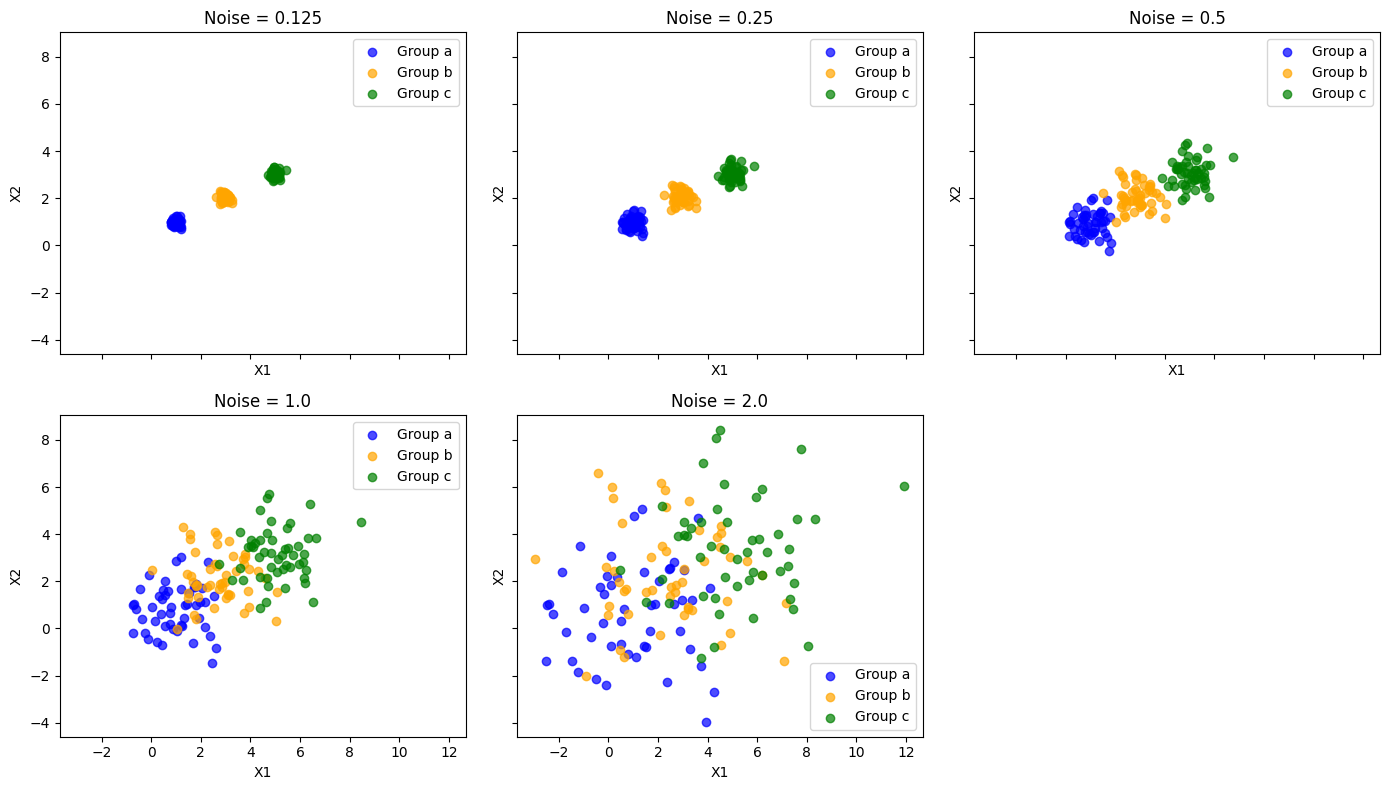

In [3]:
# Making one scatterplot for each noise level
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()

# Use the same color for each group in every plot
colors = {'a': 'blue', 'b': 'orange', 'c': 'green'}

for ax, (noise, df) in zip(axes, datasets.items()):
    # Plot each group separately so it gets its own color
    for group in ['a', 'b', 'c']:
        group_data = df[df['group'] == group]
        ax.scatter(
            group_data['x1'],
            group_data['x2'],
            color=colors[group],
            label=f'Group {group}',
            alpha=0.7
        )

    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.legend()

# Turn off the unused sixth plot
axes[5].axis('off')

plt.tight_layout()
plt.show()

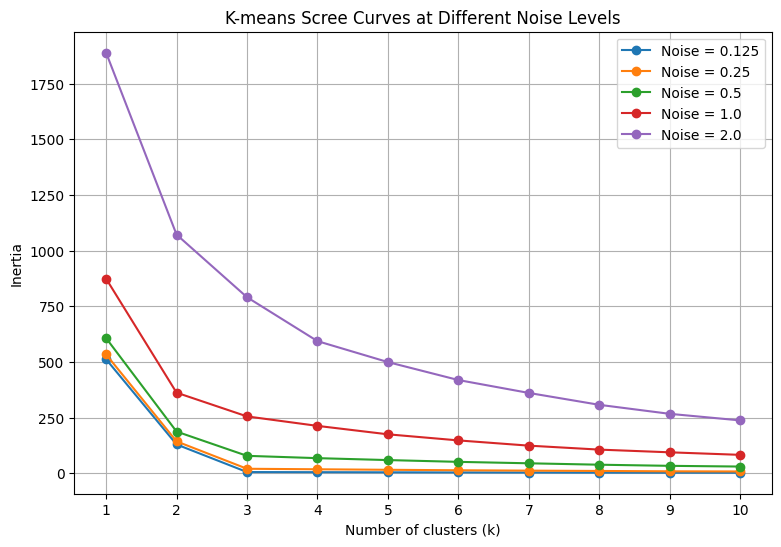

In [4]:
# Try these possible numbers of clusters
k_values = range(1, 11)

# Save the inertia values for each noise level
inertia_results = {}

for noise, df in datasets.items():
    # K-means uses only the two numeric columns
    X = df[['x1', 'x2']]

    inertia_values = []

    for k in k_values:
        # Fit K-means and save its inertia
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    inertia_results[noise] = inertia_values


# Plot all five scree curves on the same axes
plt.figure(figsize=(9, 6))

for noise, inertia_values in inertia_results.items():
    plt.plot(k_values, inertia_values, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('K-means Scree Curves at Different Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()


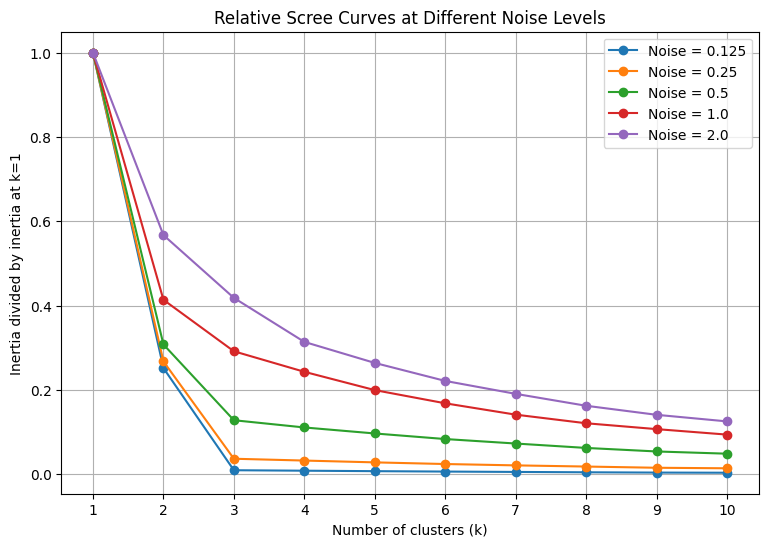

In [5]:
# Plot each curve as a fraction of its inertia when k=1
plt.figure(figsize=(9, 6))

for noise, inertia_values in inertia_results.items():
    relative_inertia = [value / inertia_values[0] for value in inertia_values]
    plt.plot(k_values, relative_inertia, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia divided by inertia at k=1')
plt.title('Relative Scree Curves at Different Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

### Findings

**Clustering with increasing noise**
* I created five datasets with three groups of 50 points each.
* The groups are centered near (1,1), (3,2), and (5,3), with noise increasing from 0.125 to 2.0 db

**Scatterplots**
* At noise levels 0.125 and 0.25, the three groups are visually distinct.
* At 0.5, the points spread out and begin to overlap.
* At 1.0, the groups are difficult to distinguish.
* At 2.0, the points overlap heavily, so the original groups are no longer visually clear.

**Scree plots**
* At low noise, the scree curve has a clearer elbow around k=3, matching the three groups used to generate the data.
* As noise increases, the elbow becomes less distinct, making the best k harder to choose confidently.

**Elbow Intuition**
* Inertia measures how close points are to their cluster centers. It gets lower as you add clusters.
* The elbow is where adding more clusters stops helping as much. Here, three clusters seem to fit the main groups.
* With more noise, the groups overlap, so it is harder to choose the best number of clusters.

## Q2

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

# Load the CSV file
df = pd.read_csv('/SIPRI Military Expenditure Database.csv')

# Keep only 2020 rows and remove rows with missing values
df2020 = df[df['Year'] == 2020].dropna().copy()

# The index column is just a row number, so I removed it
df2020 = df2020.drop(columns='index')

# Reset the row numbers after filtering
df2020 = df2020.reset_index(drop=True)

print('Number of countries:', len(df2020))
print(df2020.head())

Number of countries: 148
   Year      Country  Spending (2020 USD)  Percent of GDP  \
0  2020  Afghanistan           279.576955        0.013589   
1  2020      Albania           187.433234        0.012583   
2  2020      Algeria          9708.277440        0.066600   
3  2020       Angola           993.594405        0.014442   
4  2020    Argentina          2830.929705        0.007269   

   Percent of Government Spending  Spending per Capita  
0                        0.049728             7.181899  
1                        0.037952            65.126211  
2                        0.173924           221.392384  
3                        0.074624            30.231680  
4                        0.017268            62.636731  


In [7]:
def make_scree_plot(X, title):
    # Calculate inertia for k values from 1 through 10
    k_values = range(1, 11)
    inertia_values = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    # Plot the results
    plt.figure(figsize=(7, 5))
    plt.plot(k_values, inertia_values, marker='o')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Inertia')
    plt.title(title)
    plt.xticks(list(k_values))
    plt.grid(True)
    plt.show()

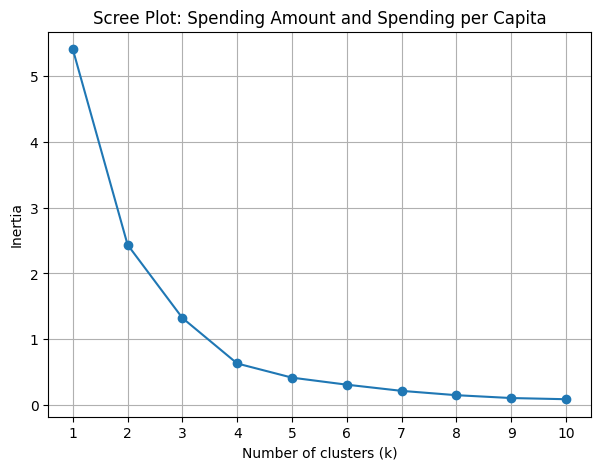

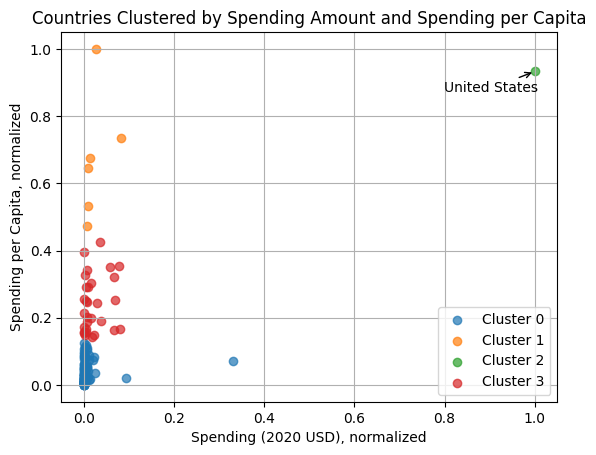

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                       1.0  778397.200000           NaN  778397.200000   
3                      30.0   17077.591354  20583.053357     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          2294.039665    5857.060906   26296.001003   61712.537169   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0    80.061470  ...                       0.083508   
1                       6.0  1706.721916  ...                       0.164503   
2                       1.0  2351.631858  ...                       0.081976   
3                      30.0   607.478618  ...                       0.048819   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027          111.0  0.017349  0.011699  0.000054  0.010087   
1        0.225050            6.0  0.059781  0.031979  0.020060  0.035460   
2        0.081976            1.0  0.037179       NaN  0.037179  0.037179   
3        0.114776           30.0  0.019397  0.009272  0.006273  0.013892   

                                       
              50%       75%       max  
cluster                                
0        0.014389  0.021697  0.066600  
1        0.059257  0.085398  0.098470  
2        0.037179  0.037179  0.037179  
3        0.018834  0.022515  0.042634  

[4 rows x 32 columns]

,Country,cluster
144,United States of America,2


In [8]:
spending_cols = ['Spending (2020 USD)', 'Spending per Capita']

# Scale both variables from 0 to 1
scaler = MinMaxScaler()
X_spending = scaler.fit_transform(df2020[spending_cols])

# Make the scree plot
make_scree_plot(X_spending, 'Scree Plot: Spending Amount and Spending per Capita')

# Four clusters is a reasonable choice from the elbow for this pair
spending_model = KMeans(n_clusters=4, random_state=42, n_init=10)
spending_labels = spending_model.fit_predict(X_spending)

# Save the cluster number beside each country's data
spending_results = df2020.copy()
spending_results['cluster'] = spending_labels

# Plot the normalized values, colored by cluster
for cluster in sorted(spending_results['cluster'].unique()):
    points = spending_labels == cluster
    plt.scatter(
        X_spending[points, 0],
        X_spending[points, 1],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

# Marks the United States on the plot
us_row = df2020.index[
    df2020['Country'] == 'United States of America'
][0]

plt.annotate(
    'United States',
    (X_spending[us_row, 0], X_spending[us_row, 1]),
    xytext=(-65, -15),
    textcoords='offset points',
    arrowprops={'arrowstyle': '->'}
)

plt.xlabel('Spending (2020 USD), normalized')
plt.ylabel('Spending per Capita, normalized')
plt.title('Countries Clustered by Spending Amount and Spending per Capita')
plt.legend()
plt.grid(True)
plt.show()

# Compare the original, unscaled values within each cluster
display(spending_results.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]].describe())

# Check the United States' cluster
display(spending_results[
    spending_results['Country'] == 'United States of America'
][['Country', 'cluster']])

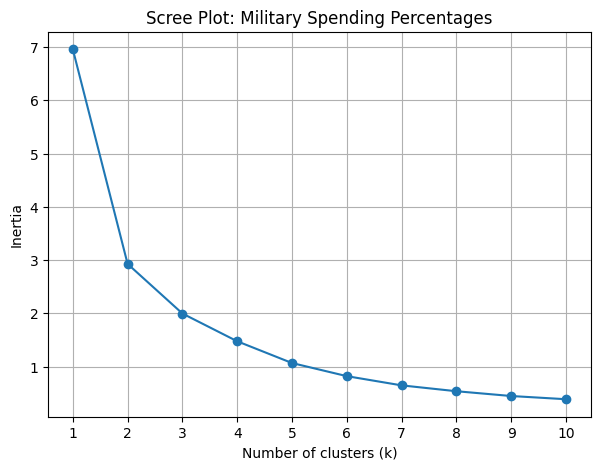

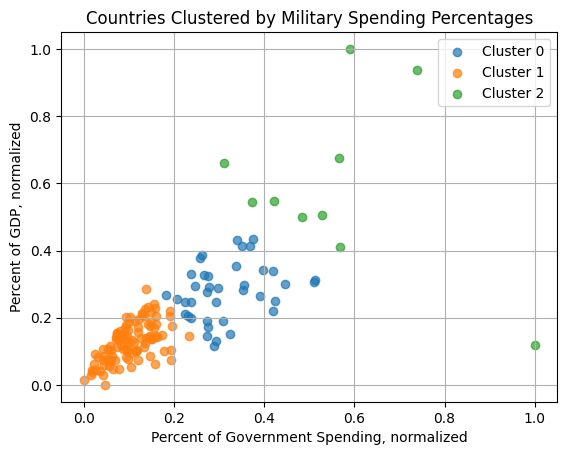

Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      39.0  27387.150069  124489.244263   44.348098   
1                      99.0   7611.174172   27958.296403    8.622460   
2                      10.0  12514.955945   19365.712246  633.960400   

                                                                \
                 25%          50%           75%            max   
cluster                                                          
0         310.624359  1157.372367   5786.787259  778397.200000   
1         121.641398   567.650747   3910.107493  257973.429834   
2        2101.377796  6518.375529  10222.946276   64558.400000   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                            75%   
cluster                                  ...                                  
0                      39.0  271.264618  ...                       0.112633   
1                      99.0  211.624304  ...                       0.047402   
2                      10.0  817.301890  ...                       0.179081   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.157918           39.0  0.027412  0.008191  0.011317  0.021254   
1        0.074624           99.0  0.012664  0.005681  0.000054  0.008393   
2        0.303027           10.0  0.058071  0.024867  0.011742  0.049297   

                                       
              50%       75%       max  
cluster                                
0        0.027781  0.032461  0.042810  
1        0.013191  0.016752  0.028132  
2        0.053729  0.066190  0.098470  

[3 rows x 32 columns]

,Country,cluster
144,United States of America,0


In [9]:
percent_cols = ['Percent of Government Spending', 'Percent of GDP']

# Scale both variables from 0 to 1
scaler = MinMaxScaler()
X_percent = scaler.fit_transform(df2020[percent_cols])

# Make the scree plot
make_scree_plot(X_percent, 'Scree Plot: Military Spending Percentages')

# Three clusters is a reasonable choice for this pair
percent_model = KMeans(n_clusters=3, random_state=42, n_init=10)
percent_labels = percent_model.fit_predict(X_percent)

percent_results = df2020.copy()
percent_results['cluster'] = percent_labels

# Plot the normalized values, colored by cluster
for cluster in sorted(percent_results['cluster'].unique()):
    points = percent_labels == cluster
    plt.scatter(
        X_percent[points, 0],
        X_percent[points, 1],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

plt.xlabel('Percent of Government Spending, normalized')
plt.ylabel('Percent of GDP, normalized')
plt.title('Countries Clustered by Military Spending Percentages')
plt.legend()
plt.grid(True)
plt.show()

# Compare the original values within each cluster
display(percent_results.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]].describe())

# Check the United States' cluster
display(percent_results[
    percent_results['Country'] == 'United States of America'
][['Country', 'cluster']])

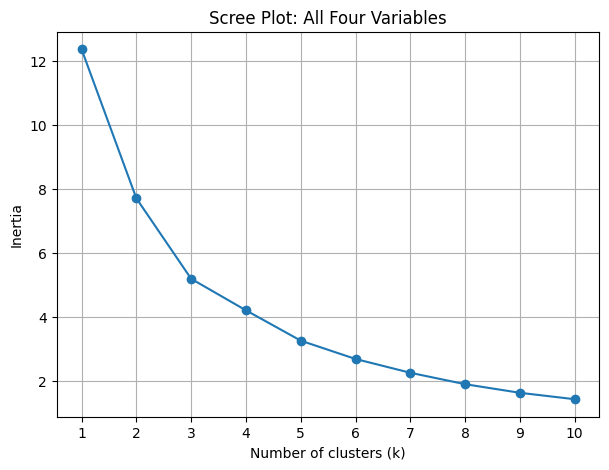

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      31.0    8786.086602   17901.909108   162.373364   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                     111.0    7086.472777   26479.379918     8.622460   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         467.787851   1404.787234   7739.166193   72937.064048   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         130.010211    567.650747   3910.107493  257973.429834   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      31.0   212.689100  ...                       0.134663   
1                       6.0  1875.150751  ...                       0.164503   
2                     111.0   196.926833  ...                       0.050505   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                       
              50%       75%       max  
cluster                                
0        0.032024  0.040531  0.066600  
1        0.059257  0.085398  0.098470  
2        0.013589  0.017769  0.028132  

[3 rows x 32 columns]

,Country,cluster
144,United States of America,1


,Country,cluster
66,Israel,1
75,Kuwait,1
106,Oman,1
117,Saudi Arabia,1
122,Singapore,1
144,United States of America,1


In [10]:
all_cols = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

# Scale all four variables from 0 to 1
scaler = MinMaxScaler()
X_all = scaler.fit_transform(df2020[all_cols])

# Make the scree plot
make_scree_plot(X_all, 'Scree Plot: All Four Variables')

# Three clusters is a reasonable choice from this scree plot
all_model = KMeans(n_clusters=3, random_state=42, n_init=10)
all_labels = all_model.fit_predict(X_all)

all_results = df2020.copy()
all_results['cluster'] = all_labels

# Compare the original values within each cluster
display(all_results.groupby('cluster')[all_cols].describe())

# See which cluster contains the United States
display(all_results[
    all_results['Country'] == 'United States of America'
][['Country', 'cluster']])

# List the countries in the United States' cluster
us_cluster = all_results.loc[
    all_results['Country'] == 'United States of America',
    'cluster'
].iloc[0]

display(all_results[all_results['cluster'] == us_cluster][['Country', 'cluster']])

### Findings:

**Cleaning**
* Filtering to 2020 and dropping rows with missing values leaves 148 countries
* The index column is a row number, so it should be removed. Keep Country to identify cluster members, but exclude it, Year, and index from clustering.
* The four spending variables are already numeric. The percentage columns are stored as proportions: for example, 0.08 means 8%.
* The US has an unusually high spending amount. I kept it because it is meaningful data, but it can affect the clusters.

**Spending Amount & Spending Per Capita**
* I chose k=4 based on the elbow in the scree plot.
* The clusters broadly separate countries with lower spending, higher spending per person, and larger overall budgets.
* The US is by itself in one cluster because its total military spending is much higher than the other countries.

**Percent of government spending and percent of GDP**
* I chose k=3 based on the scree plot.
* The clusters broadly represent lower, middle, and higher military spending as a share of government spending and GDP.
* The US falls in the middle group here

**All four variables**
* I chose k=3 based on the scree plot.
* The US clusters with Israel, Kuwait, Oman, Saudi Arabia, and Singapore
* Most countries fall into a larger cluster with lower percentage shares, but smaller groups have higher values on some or all of the measures.
* The cluster numbers are arbitrary labels, it is better to look at each cluster's profile

**Overall Summary**
* K-means identifies broad similarities between countries, but the results change depending on which variables are included.
* Total spending highlights countries with large military budgets. The percentage variables show military spending relative to a country's economy or government budget.




- **Phase 1 commit SHA ID:** 9994428
- **AI tool and model used:** GitHub Copilot (the specific model name was not exposed in this session).

- **Phase 1 commit SHA ID:** 9994428
- **AI tool and model used:** [To be provided]

### *Prompts used

1. I finished Phase 1 of this clustering assignment without AI. Please help me complete the Phase 2 section. Keep my Phase 1 work unchanged, review what I did, and give me a short numbered list of improvements before writing the full revised solution for Q1 and Q2. Please keep the clustering choices explainable and make the data-loading code work both in Colab and in this project folder.
2. I wrote Phase 1 in Colab, so the file path format I used there does work. Please carry on with the Phase 2 request without changing Phase 1. In the final solution, preserve the three feature comparisons, explain the elbow choices, and use any extra clustering metric as supporting evidence rather than treating it as a definitive answer.

### *AI-proposed changes


1. Keep Phase 1 frozen and put the revised, complete Q1 and Q2 analysis in Phase 2.
2. Make CSV loading portable across the Colab upload location and the repository's `data/` folder; drop the optional row-number column only when it exists.
3. Check the required columns, numeric types, missing values, and 2020 country count before fitting models.
4. Reuse a deterministic scree-and-clustering workflow with min-max scaling applied separately to each requested feature set.
5. Preserve the original elbow-based choices (`k=4`, `k=3`, and `k=3`) but report silhouette scores as a secondary diagnostic and avoid calling either criterion definitive.
6. Keep labels aligned with country rows, show cluster summaries in the original units, and report the U.S. cluster and member countries when relevant.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Keep Phase 1 unchanged and provide the full revised analysis in Phase 2. | Accept | Preserves the assignment's before/after comparison; Phase 1 cells are not edited. |
| 2. Search both the Colab upload locations and the project `data/` folder; remove `index` only if present. | Modify | The original path is valid in my Colab workflow, so Phase 2 keeps it as a fallback and also supports the local project path. The optional index column is not a clustering feature. |
| 3. Validate required columns and numeric values, then report the cleaned 2020 row and country counts. | Accept | Makes data-cleaning assumptions visible and lets me check the expected 148-country result before modeling. |
| 4. Reuse deterministic scaling, scree, and fit steps for all feature sets. | Accept | Reduces repeated code and makes the comparisons consistent; fixed `random_state` and `n_init` make runs reproducible. |
| 5. Keep the elbow selections and add silhouette scores. | Modify | Retains my visual choices (`4`, `3`, `3`); silhouette is supplementary because it can favor a different `k` and is not a ground-truth test. The final cell prints the scores alongside the scree plots. |
| 6. Report original-unit cluster profiles and identify the U.S. from its country row. | Accept | The summaries remain interpretable after normalized fitting, and row-aligned labels avoid relying on a fragile positional lookup. The final cell displays the U.S. cluster and its members. |

### *AI-assisted solution in full
Phase 1 remains frozen. The following Phase 2 cells provide the complete revised Q1 and Q2 solutions, incorporating the accepted changes above.

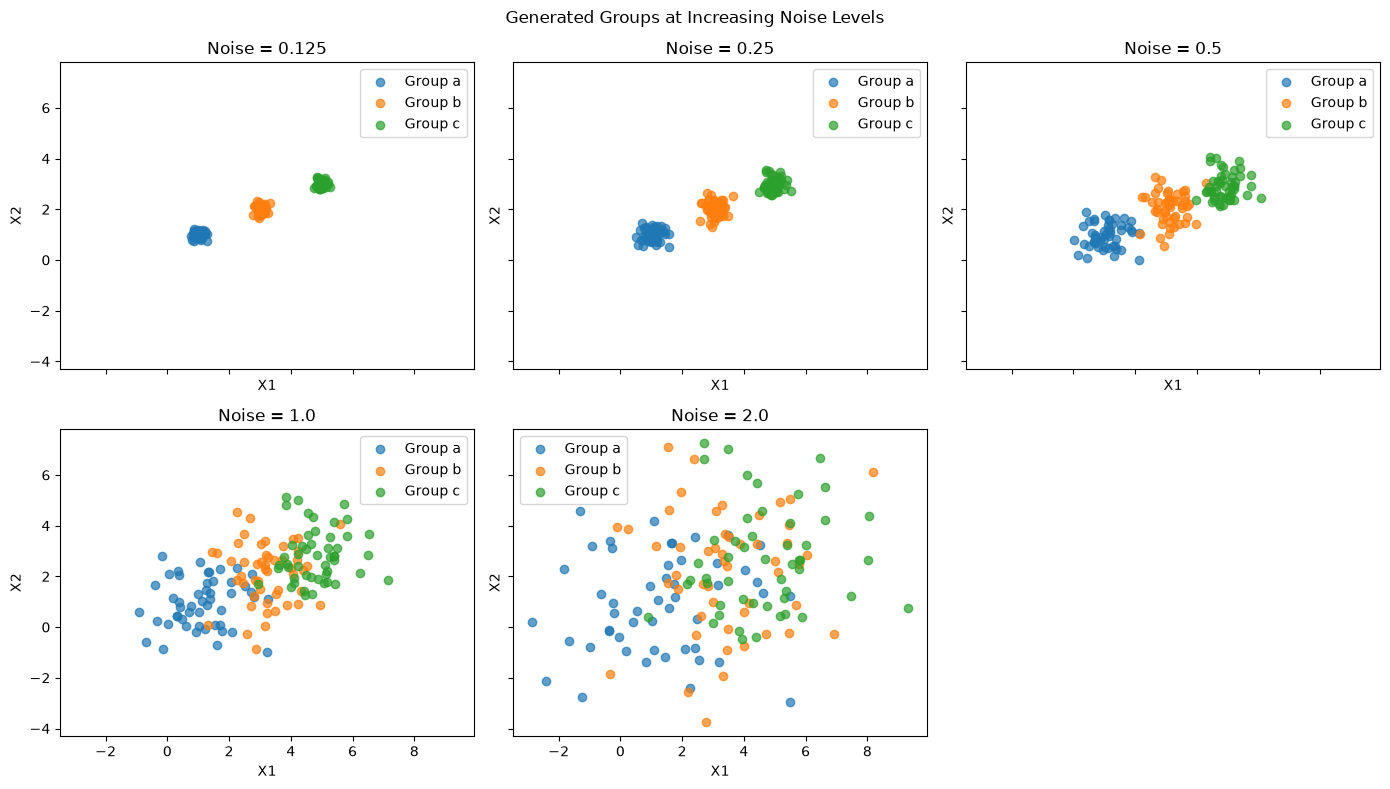

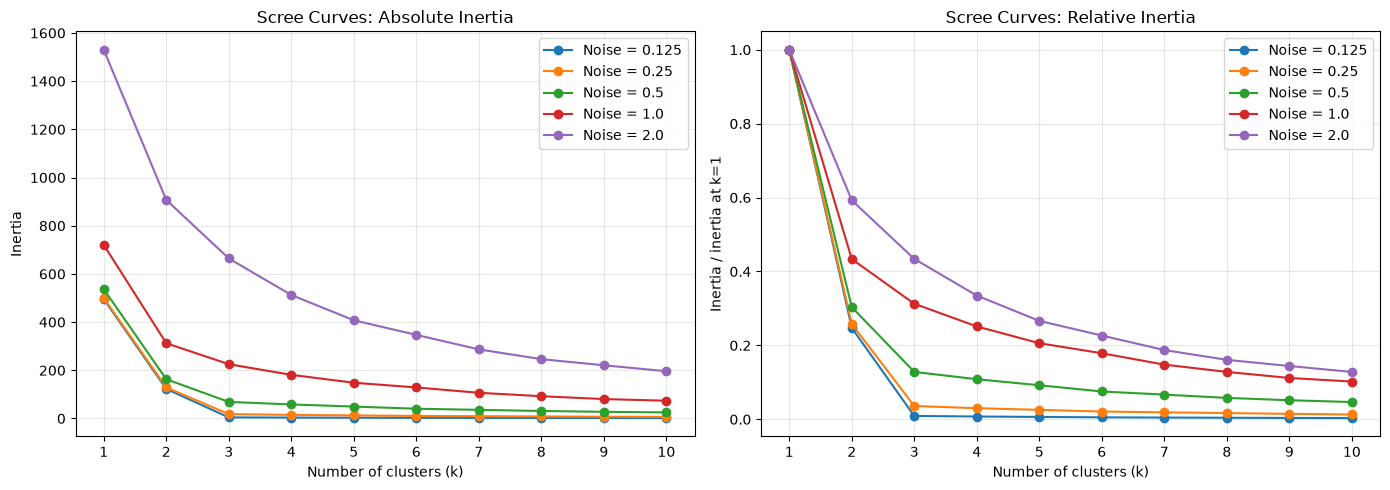

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from pathlib import Path


def createData(noise, N=50):
    rng = np.random.default_rng(100)
    centers = [(1, 1), (3, 2), (5, 3)]
    groups = []
    for group_name, (center_x, center_y) in zip(['a', 'b', 'c'], centers):
        groups.append(pd.DataFrame({
            'x1': rng.normal(center_x, noise, N),
            'x2': rng.normal(center_y, noise, N),
            'group': group_name
        }))
    return pd.concat(groups, ignore_index=True)


noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]
datasets = {noise: createData(noise) for noise in noise_levels}

# Compare the known generating groups as noise increases.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()
colors = {'a': 'tab:blue', 'b': 'tab:orange', 'c': 'tab:green'}

for axis, (noise, data) in zip(axes, datasets.items()):
    for group_name, color in colors.items():
        group_data = data[data['group'] == group_name]
        axis.scatter(group_data['x1'], group_data['x2'], color=color,
                     label=f'Group {group_name}', alpha=0.7)
    axis.set_title(f'Noise = {noise}')
    axis.set_xlabel('X1')
    axis.set_ylabel('X2')
    axis.legend()

axes[-1].axis('off')
fig.suptitle('Generated Groups at Increasing Noise Levels')
fig.tight_layout()
plt.show()

# Inertia always decreases with k; relative inertia helps compare noise levels.
k_values = range(1, 11)
inertia_results = {}
for noise, data in datasets.items():
    features = data[['x1', 'x2']]
    inertia_results[noise] = [
        KMeans(n_clusters=k, random_state=42, n_init=10).fit(features).inertia_
        for k in k_values
    ]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for noise, inertia_values in inertia_results.items():
    axes[0].plot(k_values, inertia_values, marker='o', label=f'Noise = {noise}')
    relative_inertia = np.array(inertia_values) / inertia_values[0]
    axes[1].plot(k_values, relative_inertia, marker='o', label=f'Noise = {noise}')

axes[0].set(title='Scree Curves: Absolute Inertia', xlabel='Number of clusters (k)', ylabel='Inertia')
axes[1].set(title='Scree Curves: Relative Inertia', xlabel='Number of clusters (k)', ylabel='Inertia / inertia at k=1')
for axis in axes:
    axis.set_xticks(list(k_values))
    axis.grid(True, alpha=0.3)
    axis.legend()
fig.tight_layout()
plt.show()


### Q1 findings

The scatterplots show three clearly separated groups at noise levels 0.125 and 0.25. At 0.5, the groups begin to overlap; at 1.0 and 2.0, the original group membership is much harder to infer from location alone. The scree curves have a sharper bend at low noise and become more gradual as noise increases, so choosing k becomes less definitive. Absolute inertia grows with the scale of the noise, which is why the relative-inertia panel is useful for comparing curve shapes. The elbow is the point where adding another cluster produces a smaller reduction in within-cluster squared distances; it is a visual heuristic, not proof of the true number of groups.

Loaded: data/SIPRI Military Expenditure Database.csv
2020 rows before dropping missing values: 173
Complete 2020 rows: 148
Unique countries: 148
Duplicate country rows: 0
Numeric feature dtypes:


,dtype
Spending (2020 USD),float64
Spending per Capita,float64
Percent of Government Spending,float64
Percent of GDP,float64


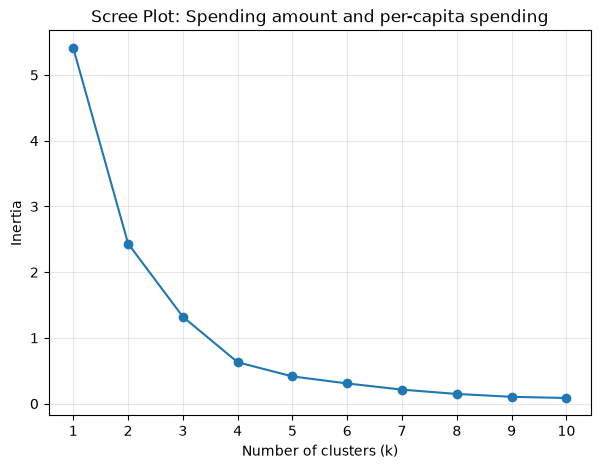

Spending amount and per-capita spending: selected k=4; silhouette score=0.701


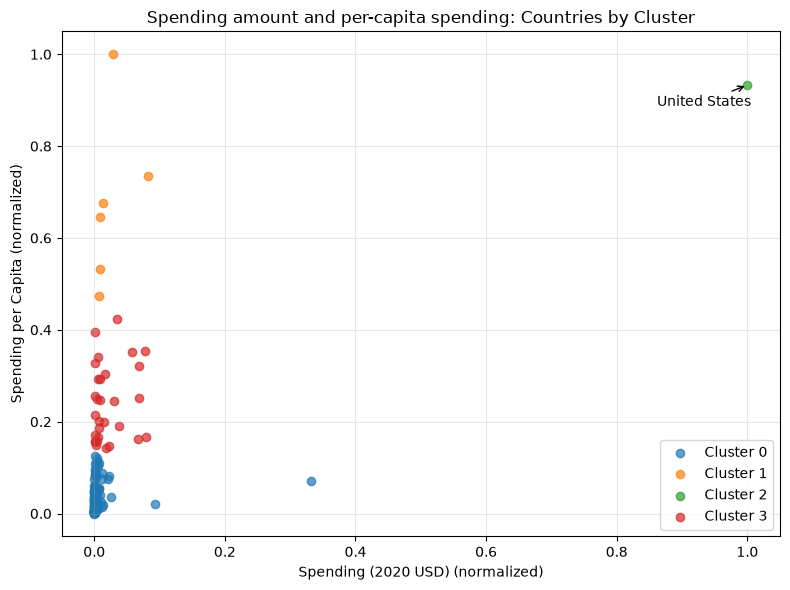

Cluster profiles for Spending amount and per-capita spending (original units):


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                       1.0  778397.200000           NaN  778397.200000   
3                      30.0   17077.591354  20583.053357     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          2294.039665    5857.060906   26296.001003   61712.537169   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0    80.061470  ...                       0.083508   
1                       6.0  1706.721916  ...                       0.164503   
2                       1.0  2351.631858  ...                       0.081976   
3                      30.0   607.478618  ...                       0.048819   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027          111.0  0.017349  0.011699  0.000054  0.010087   
1        0.225050            6.0  0.059781  0.031979  0.020060  0.035460   
2        0.081976            1.0  0.037179       NaN  0.037179  0.037179   
3        0.114776           30.0  0.019397  0.009272  0.006273  0.013892   

                                       
              50%       75%       max  
cluster                                
0        0.014389  0.021697  0.066600  
1        0.059257  0.085398  0.098470  
2        0.037179  0.037179  0.037179  
3        0.018834  0.022515  0.042634  

[4 rows x 32 columns]

United States cluster for Spending amount and per-capita spending:


,Country,cluster
144,United States of America,2


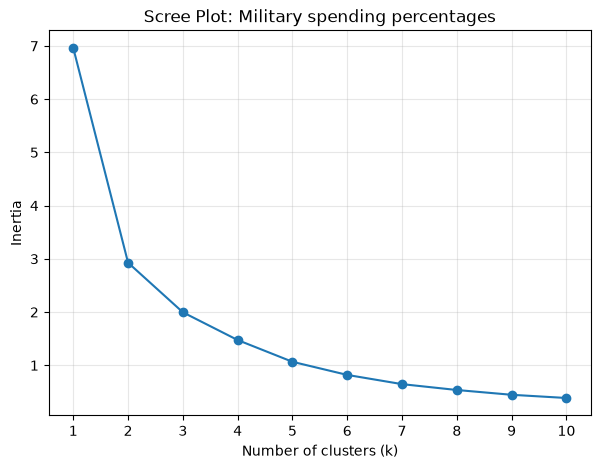

Military spending percentages: selected k=3; silhouette score=0.539


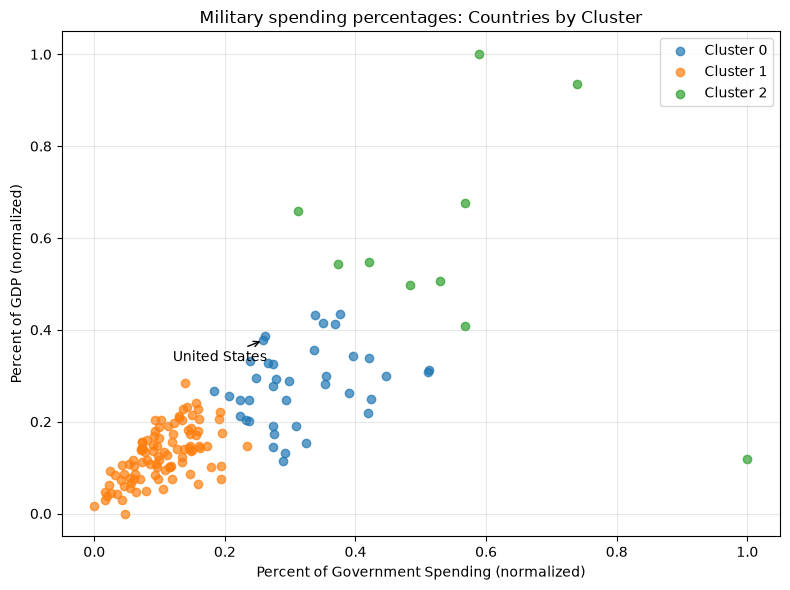

Cluster profiles for Military spending percentages (original units):


Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      39.0  27387.150069  124489.244263   44.348098   
1                      99.0   7611.174172   27958.296403    8.622460   
2                      10.0  12514.955945   19365.712246  633.960400   

                                                                \
                 25%          50%           75%            max   
cluster                                                          
0         310.624359  1157.372367   5786.787259  778397.200000   
1         121.641398   567.650747   3910.107493  257973.429834   
2        2101.377796  6518.375529  10222.946276   64558.400000   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                            75%   
cluster                                  ...                                  
0                      39.0  271.264618  ...                       0.112633   
1                      99.0  211.624304  ...                       0.047402   
2                      10.0  817.301890  ...                       0.179081   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.157918           39.0  0.027412  0.008191  0.011317  0.021254   
1        0.074624           99.0  0.012664  0.005681  0.000054  0.008393   
2        0.303027           10.0  0.058071  0.024867  0.011742  0.049297   

                                       
              50%       75%       max  
cluster                                
0        0.027781  0.032461  0.042810  
1        0.013191  0.016752  0.028132  
2        0.053729  0.066190  0.098470  

[3 rows x 32 columns]

United States cluster for Military spending percentages:


,Country,cluster
144,United States of America,0


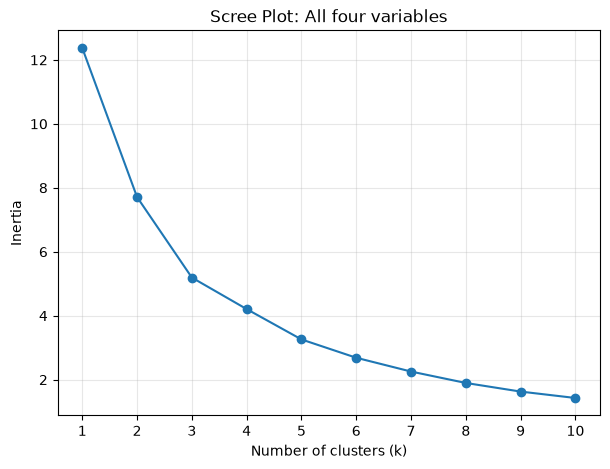

All four variables: selected k=3; silhouette score=0.480


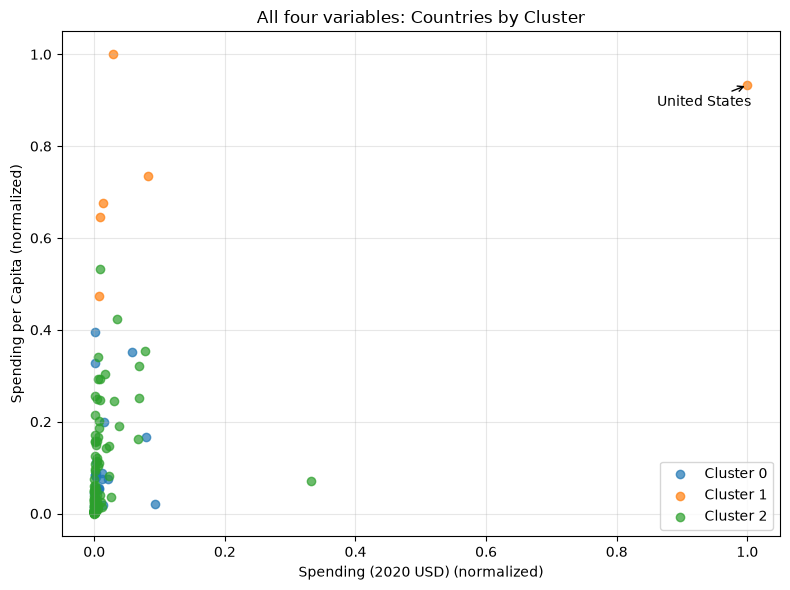

Cluster profiles for All four variables (original units):


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      31.0    8786.086602   17901.909108   162.373364   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                     111.0    7086.472777   26479.379918     8.622460   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         467.787851   1404.787234   7739.166193   72937.064048   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         130.010211    567.650747   3910.107493  257973.429834   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      31.0   212.689100  ...                       0.134663   
1                       6.0  1875.150751  ...                       0.164503   
2                     111.0   196.926833  ...                       0.050505   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                       
              50%       75%       max  
cluster                                
0        0.032024  0.040531  0.066600  
1        0.059257  0.085398  0.098470  
2        0.013589  0.017769  0.028132  

[3 rows x 32 columns]

United States cluster for All four variables:


,Country,cluster
144,United States of America,1


Countries in the United States cluster using all four variables:


,Country,cluster
0,Israel,1
1,Kuwait,1
2,Oman,1
3,Saudi Arabia,1
4,Singapore,1
5,United States of America,1


In [2]:
# Locate the CSV in either the project folder or common Colab upload locations.
from pathlib import Path

csv_name = 'SIPRI Military Expenditure Database.csv'
candidate_paths = [
    Path('data') / csv_name,
    Path(csv_name),
    Path('/content') / csv_name,
    Path('/') / csv_name,
]
data_path = next((path for path in candidate_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        f'Could not find {csv_name}. Checked: '
        + ', '.join(str(path) for path in candidate_paths)
    )

raw_df = pd.read_csv(data_path)
feature_columns = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP',
]
required_columns = ['Year', 'Country', *feature_columns]
missing_columns = [column for column in required_columns if column not in raw_df.columns]
if missing_columns:
    raise ValueError(f'Missing required CSV columns: {missing_columns}')

# The exported row-number column is an identifier, not a clustering feature.
raw_df = raw_df.drop(columns=['index'], errors='ignore')
df2020 = raw_df.loc[raw_df['Year'].eq(2020)].copy()
for column in feature_columns:
    df2020[column] = pd.to_numeric(df2020[column], errors='coerce')

rows_before_dropna = len(df2020)
df2020 = df2020.dropna().reset_index(drop=True)
print(f'Loaded: {data_path}')
print(f'2020 rows before dropping missing values: {rows_before_dropna}')
print(f'Complete 2020 rows: {len(df2020)}')
print(f'Unique countries: {df2020["Country"].nunique()}')
print(f'Duplicate country rows: {df2020["Country"].duplicated().sum()}')
print('Numeric feature dtypes:')
display(df2020[feature_columns].dtypes.to_frame('dtype'))

if df2020.empty:
    raise ValueError('No complete 2020 records remain after cleaning.')
if df2020[feature_columns].isna().any().any():
    raise ValueError('Missing numeric feature values remain after cleaning.')


def plot_scree(features, title):
    candidate_ks = range(1, min(10, len(features)) + 1)
    inertias = []
    for cluster_count in candidate_ks:
        model = KMeans(n_clusters=cluster_count, random_state=42, n_init=10)
        model.fit(features)
        inertias.append(model.inertia_)

    plt.figure(figsize=(7, 5))
    plt.plot(list(candidate_ks), inertias, marker='o')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Inertia')
    plt.title(title)
    plt.xticks(list(candidate_ks))
    plt.grid(True, alpha=0.3)
    plt.show()
    return list(candidate_ks), inertias


def analyze_feature_set(name, columns, chosen_k, scatter_columns):
    scaler = MinMaxScaler()
    scaled_values = scaler.fit_transform(df2020[columns])
    plot_scree(scaled_values, f'Scree Plot: {name}')

    model = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_values)
    results = df2020.copy()
    results['cluster'] = labels
    score = silhouette_score(scaled_values, labels)
    print(f'{name}: selected k={chosen_k}; silhouette score={score:.3f}')

    if scatter_columns:
        x_position = columns.index(scatter_columns[0])
        y_position = columns.index(scatter_columns[1])
        fig, axis = plt.subplots(figsize=(8, 6))
        for cluster_number in sorted(results['cluster'].unique()):
            in_cluster = results['cluster'].to_numpy() == cluster_number
            axis.scatter(
                scaled_values[in_cluster, x_position],
                scaled_values[in_cluster, y_position],
                label=f'Cluster {cluster_number}', alpha=0.7
            )

        us_positions = np.flatnonzero(
            results['Country'].eq('United States of America').to_numpy()
        )
        if len(us_positions):
            us_position = us_positions[0]
            axis.annotate(
                'United States',
                (scaled_values[us_position, x_position], scaled_values[us_position, y_position]),
                xytext=(-65, -15), textcoords='offset points',
                arrowprops={'arrowstyle': '->'}
            )

        axis.set_xlabel(f'{scatter_columns[0]} (normalized)')
        axis.set_ylabel(f'{scatter_columns[1]} (normalized)')
        axis.set_title(f'{name}: Countries by Cluster')
        axis.legend()
        axis.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

    print(f'Cluster profiles for {name} (original units):')
    display(results.groupby('cluster')[feature_columns].describe())

    us_rows = results.loc[
        results['Country'].eq('United States of America'), ['Country', 'cluster']
    ]
    if us_rows.empty:
        print('United States of America was not found in the cleaned data.')
    else:
        print(f'United States cluster for {name}:')
        display(us_rows)
    return results


spending_columns = ['Spending (2020 USD)', 'Spending per Capita']
percent_columns = ['Percent of Government Spending', 'Percent of GDP']

spending_results = analyze_feature_set(
    'Spending amount and per-capita spending',
    spending_columns,
    chosen_k=4,
    scatter_columns=spending_columns,
)
percent_results = analyze_feature_set(
    'Military spending percentages',
    percent_columns,
    chosen_k=3,
    scatter_columns=percent_columns,
)
all_results = analyze_feature_set(
    'All four variables',
    feature_columns,
    chosen_k=3,
    scatter_columns=spending_columns,
)

us_cluster = all_results.loc[
    all_results['Country'].eq('United States of America'), 'cluster'
]
if not us_cluster.empty:
    print('Countries in the United States cluster using all four variables:')
    display(
        all_results.loc[all_results['cluster'].eq(us_cluster.iloc[0]), ['Country', 'cluster']]
        .sort_values('Country')
        .reset_index(drop=True)
    )


### Q2 findings

**Cleaning and preparation.** The loaded 2020 subset has 173 rows; dropping incomplete rows leaves 148 unique countries. The four analysis columns are numeric (`float64`). The extra `index` field is only a row number, so it is removed when present. `Country` is retained for interpretation but excluded from the features, and `Year` is used only to filter the data. The percentage measures are proportions in the source data, so a value such as 0.05 represents 5%.

**Spending amount and per-capita spending.** The selected elbow is at k=4, with a silhouette score of 0.701 for this feature set. The resulting cluster sizes are 111, 30, 6, and 1. The United States is the single-country cluster, reflecting its exceptionally large total spending. The singleton is a useful reminder that an extreme country can strongly affect min-max scaling and the resulting partition; the score does not by itself prove that four is the uniquely correct choice.

**Spending shares.** The selected elbow is at k=3, with a silhouette score of 0.539. The cluster sizes are 99, 39, and 10, broadly separating lower, intermediate, and higher spending shares. The United States is in the intermediate cluster for this feature set, rather than forming its own cluster as it did for total spending.

**All four variables.** The selected elbow is at k=3, with a silhouette score of 0.480. The cluster sizes are 111, 31, and 6. The United States is grouped with Israel, Kuwait, Oman, Saudi Arabia, and Singapore. The displayed scatterplot colors countries by the four-variable clustering but shows only total spending and per-capita spending on its axes; the model itself uses all four normalized variables.

**Overall interpretation.** Clusters change when the feature set changes: total spending isolates the United States, while percentage features place it with countries that devote comparable shares to their military. The all-variable result combines these dimensions. K-means is useful for describing broad similarities, but cluster numbers are arbitrary, the choice of k is a judgment based on the scree plot, and the result is sensitive to scaling and influential observations. The silhouette score is supporting evidence for each separate feature set, not a definitive answer or a direct policy conclusion.

### *Reflection on AI assistance
In your own words without generative AI.

I used AI to improve my file path pull to work in both collab where I wrote the initial phase 1 script and in VS code where I used AI to assist in phase 2. In my analysis I maintained the consistent workflow for the three feature sets, reports cluster profiles in original units, and adds silhouette scores alongside my elbow based choices. Using the updated AI revised analysis, my results showed that original dataset had 148 unique countries. This matches the 148 countries found in my phase 1 analysis. Phase two also showed that the US was alone in the spending based clustering, in the intermediate gruop for the percentage features, and clustered up with Israel, Kuwait, Oman, Saudi Arabia , and Singapore when the four variables were used. 

AI initially assumed that my phase 1 file path was incorrect until I prompted it that I wrote phase 1 in collab not VS code and the file path works in the collab environment. The final revised code preserves that path. The silhouette scores that AI produced were calculated for my chosen k values and were not compared across every possible k value. 

I verified the AI produced revision by checking the Q1 and Q2 cells and the Q2 checks showed 173 2020 rows before dropping missing data and 148 complete rows after. This matches my phase 1 cleaned data. The cluster membership and summary tables were also produced and corresponded with phase 1.